In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

import warnings
warnings.filterwarnings('ignore')

In [2]:
data=pd.read_csv(r"C:\Users\Nanda\Downloads\road_network.csv")
data

,road_id,road_name,road_type,length_km,lanes,speed_limit_kmh,capacity_vehicles_per_hour,has_bus_lane,has_bike_lane,surface_condition,last_maintenance_date,latitude_start,longitude_start,latitude_end,longitude_end,district,toll_rate_rp,avg_daily_traffic
0,RD-0001,Jl. Segment 1,Jalan Kolektor,4.3,4,60,5384,0,0,Cukup,2022-12-21,-6.173938,106.920654,-6.187271,106.937674,PIK,0,10833
1,RD-0002,Jl. Segment 2,Jalan Arteri,4.3,4,80,6132,0,0,Baik,2022-11-17,-6.248396,106.768647,-6.246220,106.771962,Depok,0,6921
2,RD-0003,Jl. Segment 3,Jalan Lokal,1.8,2,40,978,0,0,Cukup,2023-04-15,-6.267631,106.814963,-6.264098,106.831007,Tangerang,0,1085
3,RD-0004,Jl. Segment 4,Jalan Kolektor,1.8,4,60,4160,0,1,Rusak Berat,2022-05-17,-6.112216,106.954036,-6.122268,106.958261,Mangga Dua,0,6145
4,RD-0005,Jl. Segment 5,Jalan Tol,22.7,4,80,6600,1,0,Baik,2024-02-16,-6.349760,106.861835,-6.341074,106.856648,Sudirman,7000,8023
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,RD-0196,Jl. Segment 196,Jalan Kolektor,3.9,2,60,2198,0,1,Cukup,2024-02-02,-6.233388,106.770735,-6.214167,106.752713,Menteng,0,2138
196,RD-0197,Jl. Segment 197,Jalan Arteri,3.3,6,60,8130,1,0,Baik,2024-03-17,-6.227477,106.949193,-6.208348,106.961205,Cibubur,0,6064
197,RD-0198,Jl. Segment 198,Jalan Lingkungan,0.9,2,20,1386,0,0,Cukup,2023-09-02,-6.342497,106.741930,-6.348195,106.730341,Blok M,0,1446
198,RD-0199,Jl. Segment 199,Jalan Kolektor,5.0,4,50,4776,0,0,Cukup,2022-06-13,-6.199783,106.954992,-6.216635,106.956670,Cawang,0,6823


In [3]:
data.head()

,road_id,road_name,road_type,length_km,lanes,speed_limit_kmh,capacity_vehicles_per_hour,has_bus_lane,has_bike_lane,surface_condition,last_maintenance_date,latitude_start,longitude_start,latitude_end,longitude_end,district,toll_rate_rp,avg_daily_traffic
0,RD-0001,Jl. Segment 1,Jalan Kolektor,4.3,4,60,5384,0,0,Cukup,2022-12-21,-6.173938,106.920654,-6.187271,106.937674,PIK,0,10833
1,RD-0002,Jl. Segment 2,Jalan Arteri,4.3,4,80,6132,0,0,Baik,2022-11-17,-6.248396,106.768647,-6.246220,106.771962,Depok,0,6921
2,RD-0003,Jl. Segment 3,Jalan Lokal,1.8,2,40,978,0,0,Cukup,2023-04-15,-6.267631,106.814963,-6.264098,106.831007,Tangerang,0,1085
3,RD-0004,Jl. Segment 4,Jalan Kolektor,1.8,4,60,4160,0,1,Rusak Berat,2022-05-17,-6.112216,106.954036,-6.122268,106.958261,Mangga Dua,0,6145
4,RD-0005,Jl. Segment 5,Jalan Tol,22.7,4,80,6600,1,0,Baik,2024-02-16,-6.349760,106.861835,-6.341074,106.856648,Sudirman,7000,8023


In [4]:
data.tail()

,road_id,road_name,road_type,length_km,lanes,speed_limit_kmh,capacity_vehicles_per_hour,has_bus_lane,has_bike_lane,surface_condition,last_maintenance_date,latitude_start,longitude_start,latitude_end,longitude_end,district,toll_rate_rp,avg_daily_traffic
195,RD-0196,Jl. Segment 196,Jalan Kolektor,3.9,2,60,2198,0,1,Cukup,2024-02-02,-6.233388,106.770735,-6.214167,106.752713,Menteng,0,2138
196,RD-0197,Jl. Segment 197,Jalan Arteri,3.3,6,60,8130,1,0,Baik,2024-03-17,-6.227477,106.949193,-6.208348,106.961205,Cibubur,0,6064
197,RD-0198,Jl. Segment 198,Jalan Lingkungan,0.9,2,20,1386,0,0,Cukup,2023-09-02,-6.342497,106.741930,-6.348195,106.730341,Blok M,0,1446
198,RD-0199,Jl. Segment 199,Jalan Kolektor,5.0,4,50,4776,0,0,Cukup,2022-06-13,-6.199783,106.954992,-6.216635,106.956670,Cawang,0,6823
199,RD-0200,Jl. Segment 200,Jalan Tol,18.1,8,80,14744,1,0,Cukup,2024-01-01,-6.174337,106.778904,-6.157797,106.791170,Kemang,5000,16047


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 18 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   road_id                     200 non-null    object 
 1   road_name                   200 non-null    object 
 2   road_type                   200 non-null    object 
 3   length_km                   200 non-null    float64
 4   lanes                       200 non-null    int64  
 5   speed_limit_kmh             200 non-null    int64  
 6   capacity_vehicles_per_hour  200 non-null    int64  
 7   has_bus_lane                200 non-null    int64  
 8   has_bike_lane               200 non-null    int64  
 9   surface_condition           200 non-null    object 
 10  last_maintenance_date       200 non-null    object 
 11  latitude_start              200 non-null    float64
 12  longitude_start             200 non-null    float64
 13  latitude_end                200 non

In [6]:
data.describe()

,length_km,lanes,speed_limit_kmh,capacity_vehicles_per_hour,has_bus_lane,has_bike_lane,latitude_start,longitude_start,latitude_end,longitude_end,toll_rate_rp,avg_daily_traffic
count,200.00000,200.000000,200.000000,200.00000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,5.99450,3.335000,57.200000,4559.49000,0.190000,0.395000,-6.222513,106.858006,-6.221939,106.859040,3050.000000,5497.510000
std,6.07204,2.089162,29.161825,4157.73614,0.393285,0.490077,0.071297,0.082616,0.073120,0.082277,6461.910043,5264.646678
min,0.30000,1.000000,20.000000,404.00000,0.000000,0.000000,-6.349760,106.703131,-6.363767,106.692182,0.000000,353.000000
25%,1.90000,2.000000,40.000000,982.50000,0.000000,0.000000,-6.275835,106.792370,-6.278966,106.794568,0.000000,1167.750000
50%,3.05000,3.000000,50.000000,3112.00000,0.000000,0.000000,-6.227666,106.862516,-6.221347,106.864975,0.000000,3675.000000
75%,8.35000,4.000000,80.000000,6765.00000,0.000000,1.000000,-6.159397,106.922157,-6.163668,106.921874,0.000000,8847.250000
max,24.10000,8.000000,120.000000,15976.00000,1.000000,1.000000,-6.101649,106.998380,-6.087672,107.011265,25000.000000,28394.000000


In [4]:
data.duplicated().sum()

np.int64(0)

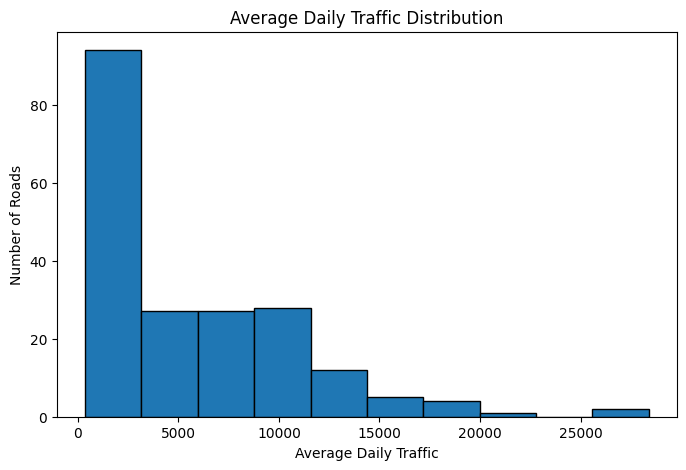

In [42]:
plt.figure(figsize=(8, 5))

plt.hist(
    data["avg_daily_traffic"],
    bins=10,
    edgecolor="black"
)

plt.title("Average Daily Traffic Distribution")
plt.xlabel("Average Daily Traffic")
plt.ylabel("Number of Roads")

plt.show()

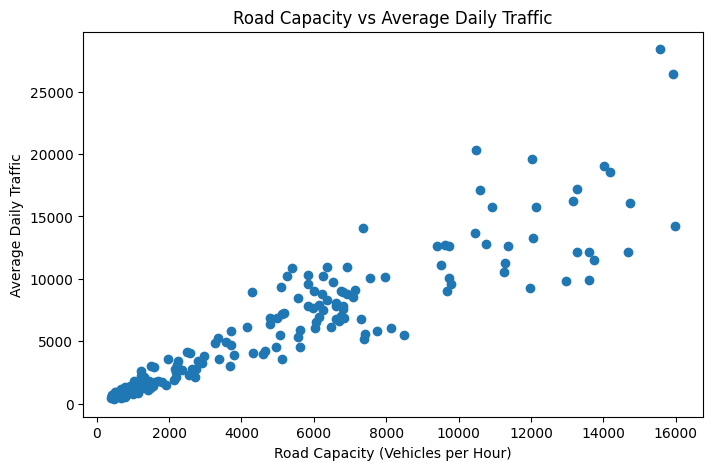

In [43]:
plt.figure(figsize=(8, 5))

plt.scatter(
    data["capacity_vehicles_per_hour"],
    data["avg_daily_traffic"]
)

plt.title("Road Capacity vs Average Daily Traffic")
plt.xlabel("Road Capacity (Vehicles per Hour)")
plt.ylabel("Average Daily Traffic")

plt.show()

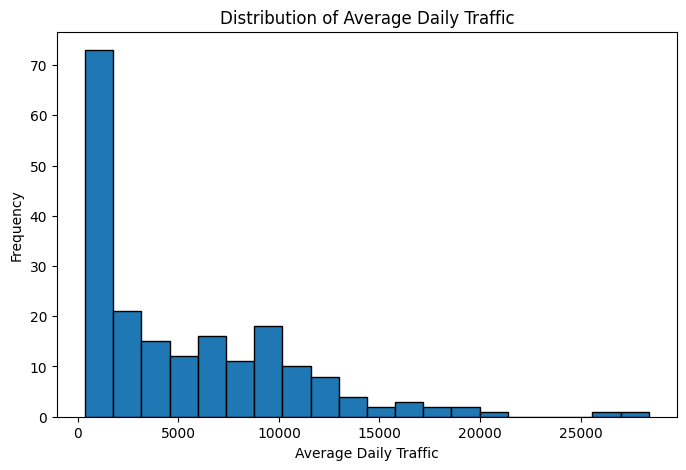

In [47]:
plt.figure(figsize=(8, 5))

plt.hist(
    data["avg_daily_traffic"],
    bins=20,
    edgecolor="black"
)

plt.xlabel("Average Daily Traffic")
plt.ylabel("Frequency")
plt.title("Distribution of Average Daily Traffic")

plt.show()

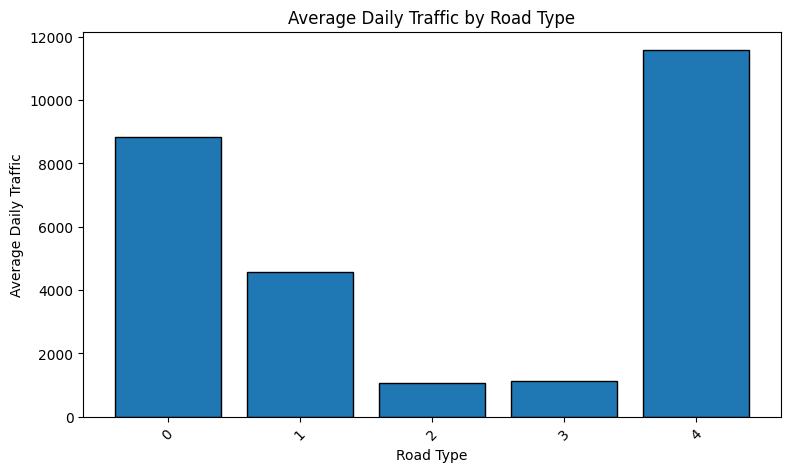

In [49]:
traffic_by_type = (
    data.groupby("road_type")["avg_daily_traffic"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(9, 5))

plt.bar(
    traffic_by_type.index,
    traffic_by_type.values,
    edgecolor="black"
)

plt.xlabel("Road Type")
plt.ylabel("Average Daily Traffic")
plt.title("Average Daily Traffic by Road Type")

plt.xticks(rotation=45)

plt.show()

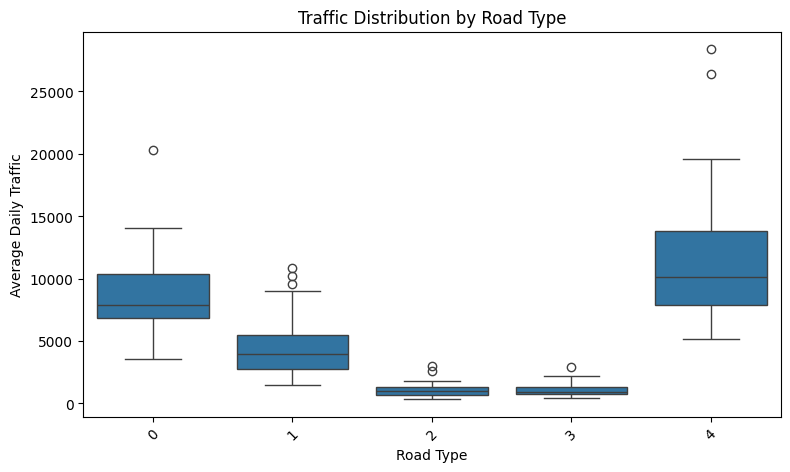

In [50]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    x="road_type",
    y="avg_daily_traffic",
    data=data
)

plt.xlabel("Road Type")
plt.ylabel("Average Daily Traffic")
plt.title("Traffic Distribution by Road Type")

plt.xticks(rotation=45)

plt.show()

In [5]:
data.isnull().sum()

road_id                       0
road_name                     0
road_type                     0
length_km                     0
lanes                         0
speed_limit_kmh               0
capacity_vehicles_per_hour    0
has_bus_lane                  0
has_bike_lane                 0
surface_condition             0
last_maintenance_date         0
latitude_start                0
longitude_start               0
latitude_end                  0
longitude_end                 0
district                      0
toll_rate_rp                  0
avg_daily_traffic             0
dtype: int64

In [6]:
data["last_maintenance_date"] = pd.to_datetime(
    data["last_maintenance_date"]
)

In [7]:
data["maintenance_year"] = (
    data["last_maintenance_date"].dt.year
)

data["maintenance_month"] = (
    data["last_maintenance_date"].dt.month
)

latest_date = data["last_maintenance_date"].max()

data["maintenance_age_days"] = (
    latest_date - data["last_maintenance_date"]
).dt.days

In [8]:
data = data.drop(
    columns=[
        "road_id",
        "road_name",
        "last_maintenance_date"
    ]
)

In [9]:
obj1 = LabelEncoder()
obj2 = LabelEncoder()
obj3 = LabelEncoder()
data["road_type"] = obj1.fit_transform(data["road_type"])

data["surface_condition"] = obj2.fit_transform(data["surface_condition"])

data["district"] = obj3.fit_transform(data["district"])

In [10]:
import joblib

##save the encoders for later use
joblib.dump(obj1,"obj1_encoder.pkl")
joblib.dump(obj2,"obj1_encoder.pkl")
joblib.dump(obj3,"obj1_encoder.pkl")

['obj1_encoder.pkl']

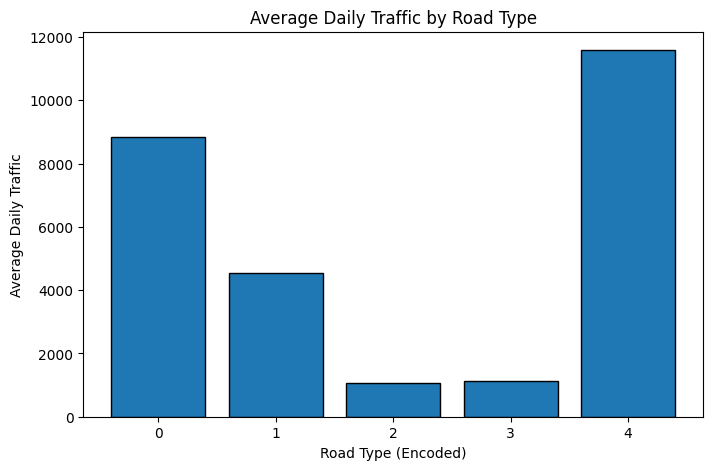

In [44]:
plt.figure(figsize=(8, 5))

road_traffic = data.groupby(
    "road_type"
)["avg_daily_traffic"].mean()

plt.bar(
    road_traffic.index,
    road_traffic.values,
    edgecolor="black"
)

plt.title("Average Daily Traffic by Road Type")
plt.xlabel("Road Type (Encoded)")
plt.ylabel("Average Daily Traffic")

plt.show()

In [12]:
data.dtypes

road_type                       int64
length_km                     float64
lanes                           int64
speed_limit_kmh                 int64
capacity_vehicles_per_hour      int64
has_bus_lane                    int64
has_bike_lane                   int64
surface_condition               int64
latitude_start                float64
longitude_start               float64
latitude_end                  float64
longitude_end                 float64
district                        int64
toll_rate_rp                    int64
avg_daily_traffic               int64
maintenance_year                int32
maintenance_month               int32
maintenance_age_days            int64
dtype: object

In [13]:
x = data.drop(
    ["avg_daily_traffic"],
    axis=1
)

y = data["avg_daily_traffic"]

In [14]:
xtrain, xtest, ytrain, ytest = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42
)
print("Training data:", xtrain.shape)
print("Testing data:", xtest.shape)

Training data: (160, 17)
Testing data: (40, 17)


In [15]:
model1 = LinearRegression()

model1.fit(
    xtrain,
    ytrain
)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [16]:
model1.predict(xtest)

array([ 6.35160934e+03,  2.60068963e+03,  3.85727184e+03,  7.12526911e+03,
        1.88154711e+04,  7.05332717e+03,  5.96997655e+03,  1.32319321e+03,
        8.23762134e+03,  4.09609263e+03,  1.11064044e+04,  7.37447480e+03,
        2.85706738e+03,  2.47092888e+03,  7.88762284e+03,  2.43768291e+03,
        2.32392896e+03,  5.91260892e+02,  1.40118399e+01,  7.93738166e+03,
        1.40026118e+04,  2.62257571e+03,  1.05184882e+04,  9.29034834e+03,
        1.33077825e+03, -1.63332290e+02,  1.01303504e+04,  5.19159266e+03,
        1.19362443e+02,  1.40656076e+04,  3.02803043e+02,  1.07641103e+04,
       -5.06720405e+01,  1.56594087e+03,  1.62946435e+03,  4.51424976e+02,
       -2.69806914e+02,  6.15664309e+03,  1.19075180e+03,  7.83996130e+03])

In [17]:
lineartrain = model1.score(
    xtrain,
    ytrain
) * 100

lineartrain

86.6510725936135

In [18]:
lineartest = model1.score(
    xtest,
    ytest
) * 100

lineartest

84.94535929306828

In [43]:
lineartrain = model1.score(xtrain, ytrain)

print("Linear Regression Training R2:", round(lineartrain, 4))

Linear Regression Training R2: 0.8665


In [44]:
lineartest = model1.score(xtest, ytest)

print("Linear Regression Testing R2:", round(lineartest, 4))

Linear Regression Testing R2: 0.8495


In [19]:
model2 = DecisionTreeRegressor(
    random_state=42
)

model2.fit(
    xtrain,
    ytrain
)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [20]:
model2.predict(xtest)

array([ 4556.,  1484.,  3393.,  9552., 28394.,  6540.,  3231.,  1381.,
        5357.,  1338.,  6540.,  6766.,   767.,  1694.,  6766.,  1694.,
        1228.,   803.,  1227.,  5357.,  9299.,  1338.,  6064., 10256.,
        1234.,   884., 14044.,  3016.,  1254., 20287.,   594., 12710.,
         823.,   697.,  1068.,   534.,  1402.,  3556.,  1791.,  6659.])

In [21]:
Treetrain = model2.score(
    xtrain,
    ytrain
) * 100

Treetrain

100.0

In [22]:
treetest = model2.score(
    xtest,
    ytest
) * 100

treetest

41.13218899286938

In [45]:
Treetrain = model2.score(xtrain, ytrain)

print("Decision Tree Training R2:", round(Treetrain, 4))

Decision Tree Training R2: 1.0


In [46]:
treetest = model2.score(xtest, ytest)

print("Decision Tree Testing R2:", round(treetest, 4))

Decision Tree Testing R2: 0.4113


In [23]:
model3 = RandomForestRegressor(
    n_estimators=50,
    random_state=42
)

model3.fit(
    xtrain,
    ytrain
)

,n_estimators,50
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [24]:
model3.predict(xtest)

array([ 5909.42,  2214.98,  4324.98,  8111.18, 20916.82,  8405.9 ,
        4357.08,  1756.32,  8015.7 ,  1950.7 ,  9042.8 ,  7628.02,
         921.12,  2433.32,  8124.72,  1456.2 ,  2429.12,   750.84,
        1063.58,  7584.54, 12628.58,  1360.  ,  9150.36,  8638.82,
        1184.92,   929.42,  8813.12,  3290.46,   985.44, 17112.4 ,
         656.24, 10956.84,   776.02,   637.54,   822.26,   806.14,
        1214.34,  5368.14,  1510.16,  8136.48])

In [25]:
foresttrain = model3.score(
    xtrain,
    ytrain
) * 100

foresttrain

97.65802158466761

In [26]:
foresttest = model3.score(
    xtest,
    ytest
) * 100

foresttest

83.98697582986834

In [47]:
foresttrain = model3.score(xtrain, ytrain)

print("Random Forest Training R2:", round(foresttrain, 4))

Random Forest Training R2: 0.9766


In [48]:
foresttest = model3.score(xtest, ytest)

print("Random Forest Testing R2:", round(foresttest, 4))

Random Forest Testing R2: 0.8399


In [27]:
model4 = GradientBoostingRegressor(
    n_estimators=50,
    random_state=42
)

model4.fit(
    xtrain,
    ytrain
)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,50
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [28]:
model4.predict(xtest)

array([ 4646.71946705,  2461.17184246,  5018.95367295,  7778.90212699,
       22172.70958602,  7587.92464728,  4412.12289876,  1613.40557102,
        8158.99113947,  2211.82126565,  8626.39177164,  8049.78995057,
         985.27959647,  2788.64496034,  7834.88344124,  1522.48250409,
        2313.3101899 ,   927.09391538,  1082.32124258,  7681.13633919,
       13903.78980934,  1733.56497477,  8839.7514667 ,  8479.11863928,
        1222.37091562,   933.03162508,  7854.76581229,  3063.54506882,
         975.68476907, 18104.79276758,   912.94712507,  9968.52238966,
        1020.75331559,   862.88600353,   878.36296052,   960.35851618,
         418.37140469,  5405.78108719,  1572.54362563,  9078.45292959])

In [29]:
gradienttrain = model4.score(
    xtrain,
    ytrain
) * 100

gradienttrain

98.16653128465401

In [30]:
gradienttest = model4.score(
    xtest,
    ytest
) * 100

gradienttest

81.53837430786425

In [49]:
gradienttrain = model4.score(xtrain, ytrain)

print("Gradient Boosting Training R2:", round(gradienttrain, 4))

Gradient Boosting Training R2: 0.9817


In [32]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import AdaBoostRegressor

In [33]:
model5 = KNeighborsRegressor(
    n_neighbors=9
)

model5.fit(
    xtrain,
    ytrain
)

,n_neighbors,9
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [34]:
knntrain = model5.score(xtrain,ytrain) * 100
knntrain

81.11122107807994

In [35]:
knntest = model5.score(xtest,ytest) * 100
knntest

93.16065072737445

In [36]:
model6 = AdaBoostRegressor(
    n_estimators=50,
    random_state=42
)

model6.fit(
    xtrain,
    ytrain
)

,estimator,None
,n_estimators,50
,learning_rate,1.0
,loss,'linear'
,random_state,42


In [37]:
adatrain = model6.score(
    xtrain,
    ytrain
) * 100

adatrain

95.11778724281395

In [38]:
adatest = model6.score(
    xtest,
    ytest
) * 100

adatest

85.39731687910032

In [39]:
knntrain = model5.score(xtrain, ytrain) * 100
knntest = model5.score(xtest, ytest) * 100

adatrain = model6.score(xtrain, ytrain) * 100
adatest = model6.score(xtest, ytest) * 100

print("KNN Training Score:", knntrain)
print("KNN Testing Score:", knntest)

print("AdaBoost Training Score:", adatrain)
print("AdaBoost Testing Score:", adatest)

KNN Training Score: 81.11122107807994
KNN Testing Score: 93.16065072737445
AdaBoost Training Score: 95.11778724281395
AdaBoost Testing Score: 85.39731687910032


In [40]:
models_score = {
    "Linear Regression": lineartest,
    "Decision Tree": treetest,
    "Random Forest": foresttest,
    "Gradient Boosting": gradienttest,
    "KNN": knntest,
    "AdaBoost": adatest
}

models_score

{'Linear Regression': 84.94535929306828,
 'Decision Tree': 41.13218899286938,
 'Random Forest': 83.98697582986834,
 'Gradient Boosting': 81.53837430786425,
 'KNN': 93.16065072737445,
 'AdaBoost': 85.39731687910032}

In [42]:
joblib.dump(model5,"KNN.pkl")

['KNN.pkl']

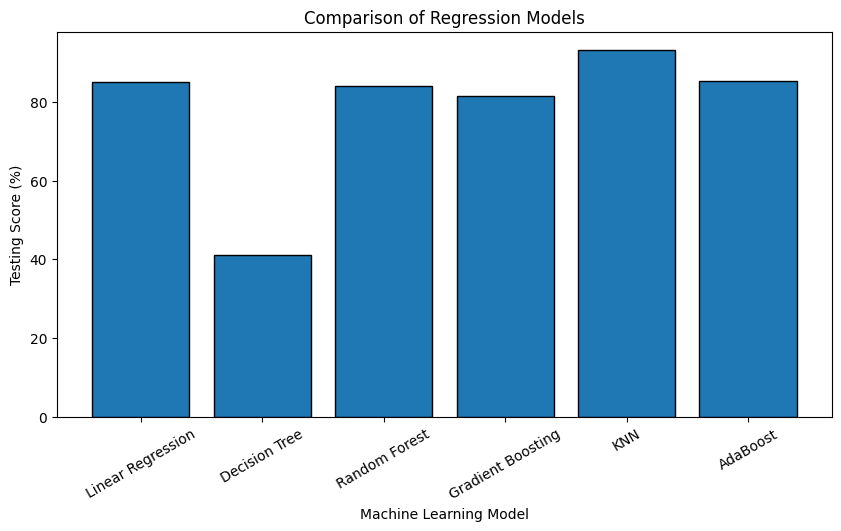

In [41]:
plt.figure(figsize=(10, 5))

plt.bar(
    models_score.keys(),
    models_score.values(),
    edgecolor="black"
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Testing Score (%)")
plt.title("Comparison of Regression Models")

plt.xticks(rotation=30)

plt.show()